Paths and reusable definitions were refactored. Stored outputs below are historical, not a fresh execution. See `docs/WORKFLOW.md` at the repository root before rerunning; several stages overwrite results or append Optuna trials.


In [ ]:
# Locate this checkout from the repository root or any notebook subdirectory.
from pathlib import Path
import sys

_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p / "src" / "steam_recommender" / "paths.py").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside the repository checkout.")
sys.path.insert(0, str(_root / "src"))
from steam_recommender import paths as _paths
if Path(_paths.__file__).resolve() != (_root / "src/steam_recommender/paths.py").resolve():
    raise RuntimeError("A different checkout is cached; restart the kernel.")
from steam_recommender.paths import project_root, project_path


# link do artykułu: https://dl.acm.org/doi/epdf/10.1145/3308560.3316457

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix

from implicit.als import AlternatingLeastSquares

import optuna

In [2]:
# Notebook:
#
# ROOT_DIR:

ROOT_DIR = project_root()

RAW_DATA_DIR = project_path("data/raw")

REPLICATION_DIR = project_path("results/literature")
RESULTS_DIR = REPLICATION_DIR / "results"
FIGURES_DIR = REPLICATION_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

USERS_ITEMS_PATH = RAW_DATA_DIR / "users_items.csv"

print("ROOT_DIR:", ROOT_DIR)
print("USERS_ITEMS_PATH:", USERS_ITEMS_PATH)
print("File exists:", USERS_ITEMS_PATH.exists())

ROOT_DIR: D:\Studiowe\Licencjat\modele
USERS_ITEMS_PATH: D:\Studiowe\Licencjat\modele\data_raw\users_items.csv
File exists: True


In [3]:
# Parametry filtracji opisane w artykule Cheuque et al.
MIN_ITEM_INTERACTIONS = 200
MIN_USER_INTERACTIONS = 100

# Próg relewantności z artykułu: 5 godzin = 300 minut
PLAYTIME_THRESHOLD = 300

# Parametry ALS raportowane w artykule
ARTICLE_FACTORS = 500
ARTICLE_REGULARIZATION = 0.01
ARTICLE_ITERATIONS = 300

# Wynik raportowany w artykule
ARTICLE_NDCG_10 = 0.332

# Optuna
USE_OPTUNA = True
N_TRIALS = 30 

# Używamy fold 0 jako validation do strojenia,
# a fold 1 jako final test po wyborze hiperparametrów.
# assign_user_folds i tak tworzy 5 foldów przez max(N_FOLDS, 5).
N_FOLDS = 2
VALIDATION_FOLD = 0
TEST_FOLD = 1

RANDOM_SEED = 42
K = 10
NUM_THREADS = 8

print("USE_OPTUNA:", USE_OPTUNA)
print("N_TRIALS:", N_TRIALS)
print("VALIDATION_FOLD:", VALIDATION_FOLD)
print("TEST_FOLD:", TEST_FOLD)
print("K:", K)

USE_OPTUNA: True
N_TRIALS: 30
VALIDATION_FOLD: 0
TEST_FOLD: 1
K: 10


In [4]:
users_items_raw = pd.read_csv(USERS_ITEMS_PATH)

print(users_items_raw.shape)
users_items_raw.head()

(5153209, 4)


,user_id,item_id,item_name,playtime_forever
0,76561197970982479,10,Counter-Strike,6
1,76561197970982479,20,Team Fortress Classic,0
2,76561197970982479,30,Day of Defeat,7
3,76561197970982479,40,Deathmatch Classic,0
4,76561197970982479,50,Half-Life: Opposing Force,0


In [5]:
users_items_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5153209 entries, 0 to 5153208
Data columns (total 4 columns):
 #   Column            Dtype
---  ------            -----
 0   user_id           str  
 1   item_id           int64
 2   item_name         str  
 3   playtime_forever  int64
dtypes: int64(2), str(2)
memory usage: 157.3 MB


In [6]:
users_items_raw.columns.tolist()

['user_id', 'item_id', 'item_name', 'playtime_forever']

In [7]:
def dataset_stats(df, name):
    n_interactions = len(df)
    n_users = df["user_id"].nunique()
    n_items = df["item_id"].nunique()
    density = n_interactions / (n_users * n_items)

    return {
        "stage": name,
        "interactions": n_interactions,
        "users": n_users,
        "items": n_items,
        "density": density,
    }

In [8]:
raw_stats = pd.DataFrame([
    dataset_stats(users_items_raw, "raw_users_items")
])

raw_stats

,stage,interactions,users,items,density
0,raw_users_items,5153209,70912,10978,0.00662


In [9]:
duplicate_pairs_count = users_items_raw.duplicated(
    subset=["user_id", "item_id"]
).sum()

duplicate_pairs_share = duplicate_pairs_count / len(users_items_raw)

print(f"Duplicate user-item rows: {duplicate_pairs_count:,}")
print(f"Duplicate share: {duplicate_pairs_share:.2%}")

Duplicate user-item rows: 59,127
Duplicate share: 1.15%


In [10]:
users_items_raw = users_items_raw.drop_duplicates(
    subset=["user_id", "item_id"],
    keep="first"
).copy()

print(f"Rows after:  {len(users_items_raw):,}")

Rows after:  5,094,082


In [11]:
def filter_item_then_user(df, min_item=200, min_user=100):
    item_counts = df["item_id"].value_counts()
    valid_items = item_counts[item_counts >= min_item].index

    after_item_filter = df[
        df["item_id"].isin(valid_items)
    ].copy()

    user_counts = after_item_filter["user_id"].value_counts()
    valid_users = user_counts[user_counts >= min_user].index

    after_user_filter = after_item_filter[
        after_item_filter["user_id"].isin(valid_users)
    ].copy()

    return after_item_filter, after_user_filter

In [12]:
after_item_filter, replication_df = filter_item_then_user(
    users_items_raw,
    min_item=MIN_ITEM_INTERACTIONS,
    min_user=MIN_USER_INTERACTIONS,
)

filtering_stats = pd.DataFrame([
    dataset_stats(users_items_raw, "raw_users_items"),
    dataset_stats(after_item_filter, "after_item_filter_min_200"),
    dataset_stats(replication_df, "after_user_filter_min_100"),
])

filtering_stats

,stage,interactions,users,items,density
0,raw_users_items,5094082,70912,10978,0.006544
1,after_item_filter_min_200,4759396,70890,2874,0.023360
2,after_user_filter_min_100,2861890,14473,2874,0.068803


In [13]:
filtering_stats.to_csv(
    RESULTS_DIR / "cheuque_filtering_stats.csv",
    index=False,
)

In [14]:
article_stats = {
    "interactions": 2_149_858,
    "users": 8_183,
    "items": 2_872,
    "density": 0.0914,
}

replication_stats = dataset_stats(
    replication_df,
    "replication_item200_user100"
)

comparison = pd.DataFrame({
    "metric": ["interactions", "users", "items", "density"],
    "article_value": [
        article_stats["interactions"],
        article_stats["users"],
        article_stats["items"],
        article_stats["density"],
    ],
    "replication_value": [
        replication_stats["interactions"],
        replication_stats["users"],
        replication_stats["items"],
        replication_stats["density"],
    ],
})

comparison["absolute_difference"] = (
    comparison["replication_value"] - comparison["article_value"]
)

comparison["relative_difference"] = (
    comparison["absolute_difference"] / comparison["article_value"]
)

comparison

,metric,article_value,replication_value,absolute_difference,relative_difference
0,interactions,2.149858e+06,2.861890e+06,712032.000000,0.331200
1,users,8.183000e+03,1.447300e+04,6290.000000,0.768667
2,items,2.872000e+03,2.874000e+03,2.000000,0.000696
3,density,9.140000e-02,6.880304e-02,-0.022597,-0.247232


In [15]:
replication_df = replication_df.copy()

replication_df["is_relevant_5h"] = (
    replication_df["playtime_forever"] >= PLAYTIME_THRESHOLD
)

relevant_count = replication_df["is_relevant_5h"].sum()
relevant_share = replication_df["is_relevant_5h"].mean()

print(f"Relevant interactions, playtime >= {PLAYTIME_THRESHOLD} min: {relevant_count:,}")
print(f"Relevant share: {relevant_share:.2%}")

Relevant interactions, playtime >= 300 min: 696,836
Relevant share: 24.35%


In [16]:
relevance_stats = pd.DataFrame({
    "metric": [
        "playtime_threshold_minutes",
        "relevant_interactions_count",
        "relevant_interactions_share",
        "non_relevant_interactions_count",
        "non_relevant_interactions_share",
    ],
    "value": [
        PLAYTIME_THRESHOLD,
        relevant_count,
        relevant_share,
        len(replication_df) - relevant_count,
        1 - relevant_share,
    ],
})

relevance_stats

,metric,value
0,playtime_threshold_minutes,3.000000e+02
1,relevant_interactions_count,6.968360e+05
2,relevant_interactions_share,2.434880e-01
3,non_relevant_interactions_count,2.165054e+06
4,non_relevant_interactions_share,7.565120e-01


In [17]:
relevance_stats.to_csv(
    RESULTS_DIR / "cheuque_relevance_threshold_5h_stats.csv",
    index=False,
)

In [18]:
replication_df.to_csv(
    RESULTS_DIR / "cheuque_replication_interactions.csv",
    index=False,
)

print("Saved:", RESULTS_DIR / "cheuque_replication_interactions.csv")

Saved: D:\Studiowe\Licencjat\modele\literature_replication\results\cheuque_replication_interactions.csv


In [19]:
user_ids = replication_df["user_id"].drop_duplicates().reset_index(drop=True)
item_ids = replication_df["item_id"].drop_duplicates().reset_index(drop=True)

user_id_to_idx = pd.Series(
    data=np.arange(len(user_ids)),
    index=user_ids,
)

item_id_to_idx = pd.Series(
    data=np.arange(len(item_ids)),
    index=item_ids,
)

idx_to_user_id = pd.Series(
    data=user_ids.values,
    index=np.arange(len(user_ids)),
)

idx_to_item_id = pd.Series(
    data=item_ids.values,
    index=np.arange(len(item_ids)),
)

n_users = len(user_ids)
n_items = len(item_ids)

print("n_users:", n_users)
print("n_items:", n_items)

n_users: 14473
n_items: 2874


In [20]:
replication_df["user_idx"] = replication_df["user_id"].map(user_id_to_idx)
replication_df["item_idx"] = replication_df["item_id"].map(item_id_to_idx)

replication_df[["user_id", "item_id", "user_idx", "item_idx", "playtime_forever", "is_relevant_5h"]].head()

,user_id,item_id,user_idx,item_idx,playtime_forever,is_relevant_5h
0,76561197970982479,10,0,0,6,False
1,76561197970982479,20,0,1,0,False
2,76561197970982479,30,0,2,7,False
3,76561197970982479,40,0,3,0,False
4,76561197970982479,50,0,4,0,False


In [21]:
def assign_user_folds(df, n_folds=5, seed=42):
    rng = np.random.default_rng(seed)

    df = df.copy()
    df["fold"] = -1

    for user_idx, user_part in df.groupby("user_idx"):
        # copy() jest ważne, bo index.to_numpy() bywa read-only
        indices = user_part.index.to_numpy().copy()
        rng.shuffle(indices)

        fold_ids = np.arange(len(indices)) % n_folds
        rng.shuffle(fold_ids)

        df.loc[indices, "fold"] = fold_ids

    return df

In [22]:
replication_df = assign_user_folds(
    replication_df,
    n_folds=max(N_FOLDS, 5),
    seed=RANDOM_SEED,
)

replication_df["fold"].value_counts().sort_index()

fold
0    578207
1    575218
2    572319
3    569497
4    566649
Name: count, dtype: int64

In [23]:
def dcg_at_k(relevance, k=10):
    relevance = np.asarray(relevance)[:k]
    if relevance.size == 0:
        return 0.0

    discounts = 1.0 / np.log2(np.arange(2, relevance.size + 2))
    return np.sum(relevance * discounts)


def ndcg_at_k(recommended_items, relevant_items, k=10):
    if len(relevant_items) == 0:
        return np.nan

    relevant_set = set(relevant_items)

    relevance = [
        1 if item in relevant_set else 0
        for item in recommended_items[:k]
    ]

    dcg = dcg_at_k(relevance, k=k)

    ideal_relevance = np.ones(min(len(relevant_set), k))
    idcg = dcg_at_k(ideal_relevance, k=k)

    if idcg == 0:
        return np.nan

    return dcg / idcg


def average_precision_at_k(recommended_items, relevant_items, k=10):
    if len(relevant_items) == 0:
        return np.nan

    relevant_set = set(relevant_items)

    hits = 0
    precision_sum = 0.0

    for rank, item in enumerate(recommended_items[:k], start=1):
        if item in relevant_set:
            hits += 1
            precision_sum += hits / rank

    return precision_sum / min(len(relevant_set), k)


def precision_at_k(recommended_items, relevant_items, k=10):
    if len(relevant_items) == 0:
        return np.nan

    relevant_set = set(relevant_items)

    hits = sum(
        1 for item in recommended_items[:k]
        if item in relevant_set
    )

    return hits / k


def recall_at_k(recommended_items, relevant_items, k=10):
    if len(relevant_items) == 0:
        return np.nan

    relevant_set = set(relevant_items)

    hits = sum(
        1 for item in recommended_items[:k]
        if item in relevant_set
    )

    return hits / len(relevant_set)

In [24]:
def build_user_item_matrix(train_df, n_users, n_items):
    rows = train_df["user_idx"].to_numpy()
    cols = train_df["item_idx"].to_numpy()

    # W replikacji traktujemy zaobserwowaną interakcję jako binarny implicit feedback.
    # Wartość 1 oznacza obecność interakcji.
    data = np.ones(len(train_df), dtype=np.float32)

    matrix = csr_matrix(
        (data, (rows, cols)),
        shape=(n_users, n_items),
    )

    matrix.sum_duplicates()
    matrix.data = np.ones_like(matrix.data, dtype=np.float32)

    return matrix

In [25]:
def evaluate_als_on_fold(
    df,
    fold_id,
    n_users,
    n_items,
    factors=500,
    regularization=0.01,
    iterations=300,
    k=10,
    random_state=42,
    num_threads=8,
):
    train_df = df[df["fold"] != fold_id].copy()
    test_df = df[df["fold"] == fold_id].copy()

    user_item_train = build_user_item_matrix(
        train_df,
        n_users=n_users,
        n_items=n_items,
    )

    model = AlternatingLeastSquares(
        factors=factors,
        regularization=regularization,
        iterations=iterations,
        random_state=random_state,
        num_threads=num_threads,
    )

    model.fit(user_item_train)

    # Relevant test items według progu 5h
    relevant_test = (
        test_df[test_df["is_relevant_5h"]]
        .groupby("user_idx")["item_idx"]
        .apply(list)
        .to_dict()
    )

    valid_users = sorted(relevant_test.keys())

    ndcg_values = []
    map_values = []
    precision_values = []
    recall_values = []

    for user_idx in valid_users:
        recommended_items, scores = model.recommend(
            userid=user_idx,
            user_items=user_item_train[user_idx],
            N=k,
            filter_already_liked_items=True,
        )

        relevant_items = relevant_test[user_idx]

        ndcg_values.append(
            ndcg_at_k(recommended_items, relevant_items, k=k)
        )

        map_values.append(
            average_precision_at_k(recommended_items, relevant_items, k=k)
        )

        precision_values.append(
            precision_at_k(recommended_items, relevant_items, k=k)
        )

        recall_values.append(
            recall_at_k(recommended_items, relevant_items, k=k)
        )

    fold_metrics = {
        "fold": fold_id,
        "users_evaluated": len(valid_users),
        f"ndcg@{k}": np.nanmean(ndcg_values),
        f"map@{k}": np.nanmean(map_values),
        f"precision@{k}": np.nanmean(precision_values),
        f"recall@{k}": np.nanmean(recall_values),
        "train_interactions": len(train_df),
        "test_interactions": len(test_df),
        "test_relevant_interactions": test_df["is_relevant_5h"].sum(),
    }

    per_user_metrics = pd.DataFrame({
        "fold": fold_id,
        "user_idx": valid_users,
        f"ndcg@{k}": ndcg_values,
        f"map@{k}": map_values,
        f"precision@{k}": precision_values,
        f"recall@{k}": recall_values,
    })

    return fold_metrics, per_user_metrics

In [26]:
def objective(trial):
    factors = trial.suggest_categorical(
        "factors",
        [32, 50, 64, 100, 150, 200, 300, 500]
    )

    regularization = trial.suggest_float(
        "regularization",
        1e-5,
        1e-1,
        log=True
    )

    iterations = trial.suggest_categorical(
        "iterations",
        [30, 50, 60, 80, 100, 150, 200, 300]
    )

    fold_metrics, _ = evaluate_als_on_fold(
        df=replication_df,
        fold_id=VALIDATION_FOLD,
        n_users=n_users,
        n_items=n_items,
        factors=factors,
        regularization=regularization,
        iterations=iterations,
        k=K,
        random_state=RANDOM_SEED,
        num_threads=NUM_THREADS,
    )

    score = fold_metrics[f"ndcg@{K}"]

    trial.set_user_attr("fold_metrics", fold_metrics)
    trial.set_user_attr("factors", factors)
    trial.set_user_attr("regularization", regularization)
    trial.set_user_attr("iterations", iterations)

    return score


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=N_TRIALS)

print("Best validation NDCG@10:", study.best_value)
print("Best params:", study.best_params)

[I 2026-05-28 20:17:02,523] A new study created in memory with name: no-name-8a5b05ac-1877-40b8-8735-52811ab93146
d:\Anaconda\envs\recommender\Lib\site-packages\implicit\cpu\als.py:95: RuntimeWarning: Intel MKL BLAS is configured to use 8 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'MKL_NUM_THREADS=1' or by callng 'threadpoolctl.threadpool_limits(1, "blas")'. Having MKL use a threadpool can lead to severe performance issues
  check_blas_config()


  0%|          | 0/300 [00:00<?, ?it/s]

[I 2026-05-28 20:17:44,303] Trial 0 finished with value: 0.2767913852090501 and parameters: {'factors': 50, 'regularization': 1.9722279683419682e-05, 'iterations': 300}. Best is trial 0 with value: 0.2767913852090501.


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-05-28 20:17:56,261] Trial 1 finished with value: 0.25869209072550575 and parameters: {'factors': 64, 'regularization': 0.0015071518318081243, 'iterations': 100}. Best is trial 0 with value: 0.2767913852090501.


...

  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-05-28 20:28:39,239] Trial 28 finished with value: 0.28331362789043507 and parameters: {'factors': 32, 'regularization': 0.016785623520453166, 'iterations': 30}. Best is trial 28 with value: 0.28331362789043507.


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-05-28 20:28:43,579] Trial 29 finished with value: 0.28321077516151427 and parameters: {'factors': 32, 'regularization': 0.003944570716717166, 'iterations': 30}. Best is trial 28 with value: 0.28331362789043507.


Best validation NDCG@10: 0.28331362789043507
Best params: {'factors': 32, 'regularization': 0.016785623520453166, 'iterations': 30}


In [27]:
optuna_trials_df = study.trials_dataframe()

optuna_trials_df.to_csv(
    RESULTS_DIR / "cheuque_als_optuna_trials.csv",
    index=False,
)

optuna_trials_df.sort_values("value", ascending=False).head(10)

,number,value,datetime_start,datetime_complete,duration,params_factors,params_iterations,params_regularization,user_attrs_factors,user_attrs_fold_metrics,user_attrs_iterations,user_attrs_regularization,state
28,28,0.283314,2026-05-28 20:28:34.873593,2026-05-28 20:28:39.239200,0 days 00:00:04.365607,32,30,0.016786,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",30,0.016786,COMPLETE
27,27,0.283311,2026-05-28 20:28:30.554445,2026-05-28 20:28:34.872574,0 days 00:00:04.318129,32,30,0.017092,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",30,0.017092,COMPLETE
29,29,0.283211,2026-05-28 20:28:39.239200,2026-05-28 20:28:43.579618,0 days 00:00:04.340418,32,30,0.003945,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",30,0.003945,COMPLETE
18,18,0.283203,2026-05-28 20:24:18.257514,2026-05-28 20:24:33.133654,0 days 00:00:14.876140,32,150,0.064725,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",150,0.064725,COMPLETE
19,19,0.283194,2026-05-28 20:24:33.133654,2026-05-28 20:24:47.908462,0 days 00:00:14.774808,32,150,0.086673,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",150,0.086673,COMPLETE
21,21,0.283190,2026-05-28 20:25:29.848547,2026-05-28 20:25:44.809657,0 days 00:00:14.961110,32,150,0.091375,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",150,0.091375,COMPLETE
17,17,0.283189,2026-05-28 20:24:03.183488,2026-05-28 20:24:18.257514,0 days 00:00:15.074026,32,150,0.096194,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",150,0.096194,COMPLETE
22,22,0.283188,2026-05-28 20:25:44.809657,2026-05-28 20:26:00.019796,0 days 00:00:15.210139,32,150,0.029815,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",150,0.029815,COMPLETE
23,23,0.283157,2026-05-28 20:26:00.019796,2026-05-28 20:26:14.887908,0 days 00:00:14.868112,32,150,0.005756,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",150,0.005756,COMPLETE
14,14,0.283080,2026-05-28 20:22:38.235662,2026-05-28 20:23:06.417906,0 days 00:00:28.182244,32,300,0.000480,32,"{'fold': 0, 'users_evaluated': 14372, 'ndcg@10...",300,0.000480,COMPLETE


In [28]:
best_params = study.best_params

best_factors = best_params["factors"]
best_regularization = best_params["regularization"]
best_iterations = best_params["iterations"]

print("Best params:")
print("factors:", best_factors)
print("regularization:", best_regularization)
print("iterations:", best_iterations)

best_test_metrics, best_test_per_user_metrics = evaluate_als_on_fold(
    df=replication_df,
    fold_id=TEST_FOLD,
    n_users=n_users,
    n_items=n_items,
    factors=best_factors,
    regularization=best_regularization,
    iterations=best_iterations,
    k=K,
    random_state=RANDOM_SEED,
    num_threads=NUM_THREADS,
)

print("Final test metrics:")
best_test_metrics

Best params:
factors: 32
regularization: 0.016785623520453166
iterations: 30


  0%|          | 0/30 [00:00<?, ?it/s]

Final test metrics:


{'fold': 1,
 'users_evaluated': 14371,
 'ndcg@10': 0.2826617389124026,
 'map@10': 0.1540260329036709,
 'precision@10': 0.2167907591677684,
 'recall@10': 0.24338558878095254,
 'train_interactions': 2286672,
 'test_interactions': 575218,
 'test_relevant_interactions': 140345}

In [29]:
article_params_test_metrics, article_params_per_user_metrics = evaluate_als_on_fold(
    df=replication_df,
    fold_id=TEST_FOLD,
    n_users=n_users,
    n_items=n_items,
    factors=ARTICLE_FACTORS,
    regularization=ARTICLE_REGULARIZATION,
    iterations=ARTICLE_ITERATIONS,
    k=K,
    random_state=RANDOM_SEED,
    num_threads=NUM_THREADS,
)

print("Article params test metrics:")
article_params_test_metrics

  0%|          | 0/300 [00:00<?, ?it/s]

Article params test metrics:


{'fold': 1,
 'users_evaluated': 14371,
 'ndcg@10': 0.08540193222480194,
 'map@10': 0.035452651287334894,
 'precision@10': 0.07078143483404077,
 'recall@10': 0.07424989004041588,
 'train_interactions': 2286672,
 'test_interactions': 575218,
 'test_relevant_interactions': 140345}

In [30]:
optuna_validation_metrics = study.best_trial.user_attrs["fold_metrics"]

comparison_rows = [
    {
        "source": "Cheuque et al. article",
        "factors": ARTICLE_FACTORS,
        "regularization": ARTICLE_REGULARIZATION,
        "iterations": ARTICLE_ITERATIONS,
        "fold": None,
        "ndcg@10": ARTICLE_NDCG_10,
        "map@10": np.nan,
        "precision@10": np.nan,
        "recall@10": np.nan,
        "users_evaluated": np.nan,
        "notes": "reported ALS result from article",
    },
    {
        "source": "ALS reported hyperparameters, reconstructed protocol",
        "factors": ARTICLE_FACTORS,
        "regularization": ARTICLE_REGULARIZATION,
        "iterations": ARTICLE_ITERATIONS,
        "fold": TEST_FOLD,
        "ndcg@10": article_params_test_metrics[f"ndcg@{K}"],
        "map@10": article_params_test_metrics[f"map@{K}"],
        "precision@10": article_params_test_metrics[f"precision@{K}"],
        "recall@10": article_params_test_metrics[f"recall@{K}"],
        "users_evaluated": article_params_test_metrics["users_evaluated"],
        "notes": "reported hyperparameters evaluated under reconstructed protocol",
    },
    {
        "source": "ALS Optuna tuned, validation fold",
        "factors": best_factors,
        "regularization": best_regularization,
        "iterations": best_iterations,
        "fold": VALIDATION_FOLD,
        "ndcg@10": optuna_validation_metrics[f"ndcg@{K}"],
        "map@10": optuna_validation_metrics[f"map@{K}"],
        "precision@10": optuna_validation_metrics[f"precision@{K}"],
        "recall@10": optuna_validation_metrics[f"recall@{K}"],
        "users_evaluated": optuna_validation_metrics["users_evaluated"],
        "notes": "best Optuna result on validation fold",
    },
    {
        "source": "ALS Optuna tuned, test fold",
        "factors": best_factors,
        "regularization": best_regularization,
        "iterations": best_iterations,
        "fold": TEST_FOLD,
        "ndcg@10": best_test_metrics[f"ndcg@{K}"],
        "map@10": best_test_metrics[f"map@{K}"],
        "precision@10": best_test_metrics[f"precision@{K}"],
        "recall@10": best_test_metrics[f"recall@{K}"],
        "users_evaluated": best_test_metrics["users_evaluated"],
        "notes": "best Optuna hyperparameters evaluated on held-out test fold",
    },
]

cheuque_optuna_comparison = pd.DataFrame(comparison_rows)

cheuque_optuna_comparison.to_csv(
    RESULTS_DIR / "cheuque_als_optuna_comparison.csv",
    index=False,
)

cheuque_optuna_comparison

,source,factors,regularization,iterations,fold,ndcg@10,map@10,precision@10,recall@10,users_evaluated,notes
0,Cheuque et al. article,500,0.010000,300,NaN,0.332000,NaN,NaN,NaN,NaN,reported ALS result from article
1,"ALS reported hyperparameters, reconstructed pr...",500,0.010000,300,1.0,0.085402,0.035453,0.070781,0.074250,14371.0,reported hyperparameters evaluated under recon...
2,"ALS Optuna tuned, validation fold",32,0.016786,30,0.0,0.283314,0.155030,0.217673,0.241831,14372.0,best Optuna result on validation fold
3,"ALS Optuna tuned, test fold",32,0.016786,30,1.0,0.282662,0.154026,0.216791,0.243386,14371.0,best Optuna hyperparameters evaluated on held-...


In [31]:
best_test_per_user_metrics.to_csv(
    RESULTS_DIR / "cheuque_als_optuna_best_test_per_user_metrics.csv",
    index=False,
)

article_params_per_user_metrics.to_csv(
    RESULTS_DIR / "cheuque_als_article_params_test_per_user_metrics.csv",
    index=False,
)

print("Saved Optuna comparison:", RESULTS_DIR / "cheuque_als_optuna_comparison.csv")
print("Saved Optuna trials:", RESULTS_DIR / "cheuque_als_optuna_trials.csv")

Saved Optuna comparison: D:\Studiowe\Licencjat\modele\literature_replication\results\cheuque_als_optuna_comparison.csv
Saved Optuna trials: D:\Studiowe\Licencjat\modele\literature_replication\results\cheuque_als_optuna_trials.csv


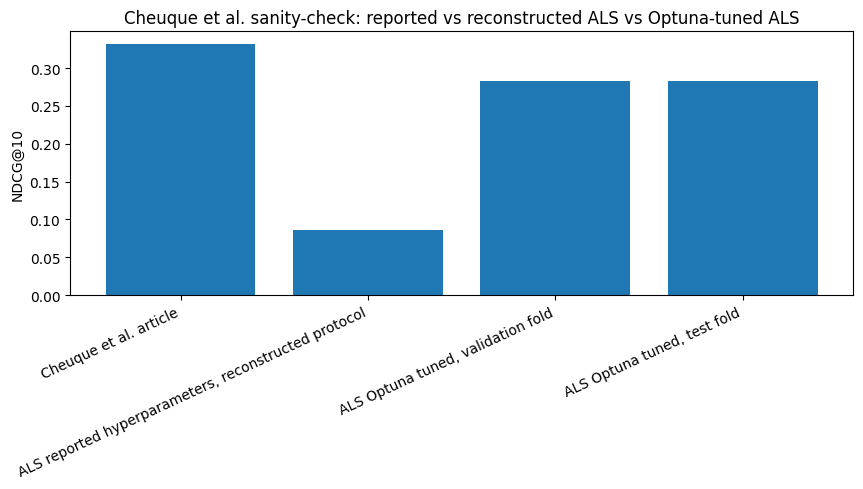

In [32]:
plot_df = cheuque_optuna_comparison.copy()

plt.figure(figsize=(9, 5))

plt.bar(
    plot_df["source"],
    plot_df["ndcg@10"],
)

plt.ylabel("NDCG@10")
plt.title("Cheuque et al. sanity-check: reported vs reconstructed ALS vs Optuna-tuned ALS")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cheuque_als_optuna_ndcg10_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()